# 1-3 로그 스케일 플로터

**오늘의 질문:** loss가 1000에서 0.001까지 줄어드는 학습 그래프, 왜 로그 스케일로 그려야 제대로 보일까?

셀을 위에서부터 하나씩 실행한다 (Shift+Enter). 결과가 나오면 채팅에 적은 예측과 비교해 보자.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

## 1. 모델 A의 loss 만들기

1000에서 시작해서 매 단계 0.9배가 된다.

- 0단계: $1000$
- 1단계: $1000 \times 0.9 = 900$
- 2단계: $1000 \times 0.9 \times 0.9 = 810$

$n$단계의 loss는 1000에 0.9를 $n$번 곱한 것이니까 $1000 \times 0.9^n$이다.

**실행하기 전에:** 0.001 밑으로 내려가려면 몇 단계쯤 걸릴지 숫자 하나를 찍어 두자.

In [2]:
steps = np.arange(0, 151)  # 0단계 ~ 150단계
loss_a = 1000 * 0.9 ** steps  # 배열에 ** 를 하면 원소마다 거듭제곱한다
print('처음 5단계:', loss_a[:5])

below = steps[loss_a < 0.001]  # loss가 0.001 밑인 단계만 골라낸다
print('0.001 밑으로 처음 내려간 단계:', below[0])
print('그때 loss:', loss_a[below[0]])

처음 5단계: [1000.   900.   810.   729.   656.1]
0.001 밑으로 처음 내려간 단계: 132
그때 loss: 0.0009120344560464496


## 2. 보통 그래프로 그리기

모델 B는 A에 0.1을 더해서 만든다. 처음엔 A와 거의 같지만, 아무리 학습해도 0.1 밑으로는 내려가지 않는다.

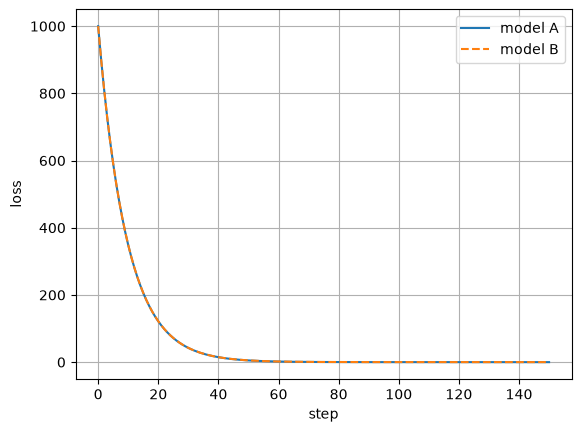

100단계  A: 0.026561  B: 0.126561
150단계  A: 0.000137  B: 0.100137


In [3]:
loss_b = loss_a + 0.1

plt.plot(steps, loss_a, label='model A')
plt.plot(steps, loss_b, label='model B', linestyle='--')
plt.xlabel('step')
plt.ylabel('loss')
plt.legend()
plt.grid(True)
plt.show()

print(f'100단계  A: {loss_a[100]:.6f}  B: {loss_b[100]:.6f}')
print(f'150단계  A: {loss_a[150]:.6f}  B: {loss_b[150]:.6f}')

그래프만 보고 A와 B를 구별할 수 있나? 숫자로 보면 150단계에서 B는 A보다 몇 배 큰가?

## 3. 확대해 보면?

세로축을 0~1로 좁혀 보자 (`plt.ylim`).

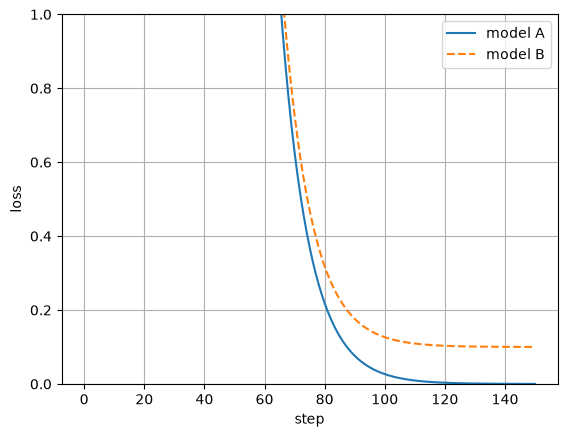

In [4]:
plt.plot(steps, loss_a, label='model A')
plt.plot(steps, loss_b, label='model B', linestyle='--')
plt.ylim(0, 1)  # 세로축을 0~1만 보여 준다
plt.xlabel('step')
plt.ylabel('loss')
plt.legend()
plt.grid(True)
plt.show()

이번엔 B가 0.1에서 멈추는 게 보인다. 대신 1000 근처는 화면 밖으로 잘렸고, A가 0.01인지 0.0001인지는 여전히 구별이 안 된다. 한 화면에 1000부터 0.001까지 다 보이게 하려면 어떻게 해야 할까?

## 4. 로그 스케일로 그리기

2번 그래프와 코드는 같고, `plt.yscale('log')` 한 줄만 더했다.

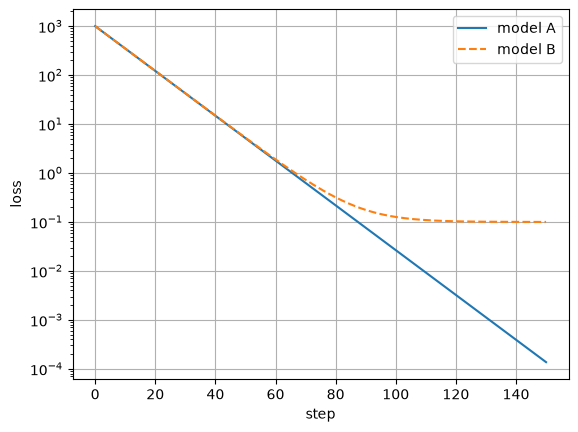

In [5]:
plt.plot(steps, loss_a, label='model A')
plt.plot(steps, loss_b, label='model B', linestyle='--')
plt.yscale('log')  # 세로축을 로그 스케일로
plt.xlabel('step')
plt.ylabel('loss')
plt.legend()
plt.grid(True)
plt.show()

세로축 눈금을 보자. $10^{-4}, 10^{-3}, \ldots, 10^{3}$이 같은 간격으로 있다. 보통 그래프는 **더해서** 같은 간격(0, 200, 400, …)이고, 로그 스케일은 **곱해서** 같은 간격(10배마다 한 칸)이다.

- 모델 A는 어떤 모양인가?
- B는 몇 단계쯤부터 A와 갈라지나?

## 5. 로그 스케일은 무엇을 한 걸까?

`np.log10(x)`는 "10을 몇 번 곱해야 $x$가 되나"를 돌려준다.

In [6]:
for x in [1000, 100, 10, 1, 0.1, 0.01, 0.001]:
    print(x, '→', np.log10(x))

1000 → 3.0
100 → 2.0
10 → 1.0
1 → 0.0
0.1 → -1.0
0.01 → -2.0
0.001 → -3.0


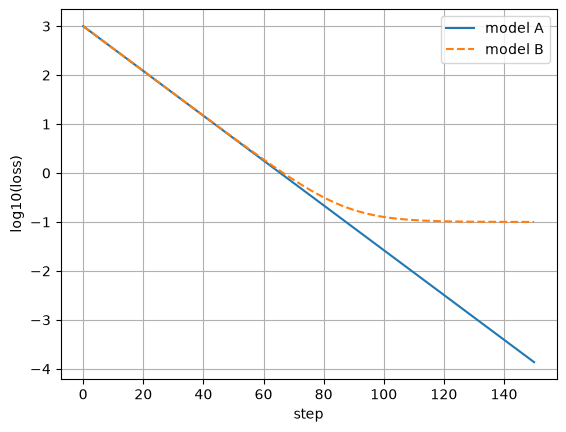

In [7]:
plt.plot(steps, np.log10(loss_a), label='model A')
plt.plot(steps, np.log10(loss_b), label='model B', linestyle='--')
plt.xlabel('step')
plt.ylabel('log10(loss)')
plt.legend()
plt.grid(True)
plt.show()

4번 그래프와 모양이 똑같다. 로그 스케일은 값에 $\log_{10}$을 씌워서 보통 그래프로 그린 것이다. 눈금에 $10^3$ 대신 $3$이라고 적혀 있을 뿐이다.

모델 A가 왜 이런 모양이 되는지는 이론 시간에 1-1의 일차함수로 풀어 본다.